# 18. Detection de Rupture (Change-Point) : inferer le moment d'un changement de regime (jumeau PyMC)

> **Serie Parite .NET <=> Python (#4956).** Ce notebook est le **jumeau Python** de `Infer-17-Change-Point.ipynb` (Infer.NET / C#, inférence EP). La specification probabiliste est **identique** ; seul le moteur d'inférence change : EP analytique cote .NET, échantillonnage **CompoundStep** (NUTS + Metropolis) cote Python, car la localisation `cp` est une variable **discrète**.

Ce notebook complète la famille des « séquences dans le temps » : il étend [PyMC-13 (Séquences / HMM)](PyMC-13-Sequences.ipynb) au cas où ce n'est pas l'état qui change à chaque instant, mais la **structure** du processus qui bascule **une seule fois** à un instant inconnu.

**Durée estimée** : 50 minutes | **Prérequis** : [PyMC-13-Sequences](PyMC-13-Sequences.ipynb) (HMM).

## 1. Motivation : la où le HMM et le filtre de Kalman s'arrêtent

[PyMC-13](PyMC-13-Sequences.ipynb) modélise une séquence où l'état caché est **discret** et change à **chaque instant**. Le filtre de Kalman ([Infer-16](../Infer/Infer-16-Kalman-Filter.ipynb)) en est le pendant **continu**. Les deux infèrent un état **récurrent** — un par pas de temps.

Le **point de rupture** est différent : l'inconnue n'est pas une trajectoire d'états, mais **un unique entier** `cp in {0, ..., N-1}` — l'indice où le processus bascule. On veut le postérieur $p(cp \mid y)$ sur cette **unique** variable structurelle, et les paramètres des deux régimes qu'elle sépare.

> *Origine.* Le **change-point bayésien** a été formalisé en message-passing sur la distribution du *run-length* par Adams & MacKay (Adams & MacKay, 2007, « Bayesian Online Changepoint Detection », *arXiv:0710.3742*). Ce notebook en est l'équivalent **off-line** : PyMC retourne d'un coup la distribution a posteriori sur la localisation de la rupture, là où Adams-MacKay fait du streaming.


In [1]:
import numpy as np
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import warnings
warnings.filterwarnings("ignore", message=".*data structure.*")
warnings.filterwarnings("ignore", message="PyTensor could not link to a BLAS")  # advisory pytensor (#3436)
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

# --- Helper reutilisable : diagnostics de convergence NON ARRONDIS (az.summary) ---
def rapport_convergence(idata, nom):
    """Rapport de convergence strict : r_hat < 1.01, ess_bulk > 400, ess_tail > 400, 0 divergence.

    round_to="none" garde les valeurs NON arrondies (round_to=None retomberait sur
    l'arrondi par defaut d'ArviZ, qui masquerait un r_hat de 1.0096). Les divergences
    ne mesurent que la partie NUTS (variables continues) ; le melange du point de
    rupture discret (Metropolis) se lit dans les r_hat / ess de la variable cp.
    """
    summ = az.summary(idata, round_to="none")
    max_rhat, var_rhat = float(summ["r_hat"].max()), summ["r_hat"].idxmax()
    min_bulk, var_bulk = float(summ["ess_bulk"].min()), summ["ess_bulk"].idxmin()
    min_tail, var_tail = float(summ["ess_tail"].min()), summ["ess_tail"].idxmin()
    ok_rhat, ok_bulk, ok_tail = max_rhat < 1.01, min_bulk > 400, min_tail > 400
    if "diverging" in idata.sample_stats:
        n_div = int(idata.sample_stats["diverging"].sum())
        ok_div = n_div == 0
        div_txt = f"{n_div} divergence(s) NUTS -> {'OK' if ok_div else 'ECHEC'} (cible = 0)"
    else:
        ok_div = None
        div_txt = "n/a (aucun pas NUTS dans ce trace) -> critere non applicable"
    print(f"=== Diagnostics de convergence : {nom} ===")
    print(f"  max r_hat    = {max_rhat:.4f}  ({var_rhat})  -> {'OK' if ok_rhat else 'ECHEC'} (cible < 1.01)")
    print(f"  min ess_bulk = {min_bulk:.1f}  ({var_bulk})  -> {'OK' if ok_bulk else 'ECHEC'} (cible > 400)")
    print(f"  min ess_tail = {min_tail:.1f}  ({var_tail})  -> {'OK' if ok_tail else 'ECHEC'} (cible > 400)")
    print(f"  divergences  : {div_txt}")
    verdict = ok_rhat and ok_bulk and ok_tail and (ok_div is not False)
    print(f"  VERDICT strict (r_hat<1.01, ess_bulk/ess_tail>400, divergences=0) : "
          f"{'CONVERGENCE OK' if verdict else 'CONVERGENCE INSUFFISANTE'}")

# --- Terrain de jeu : serie avec un SEUL changement de regime ---
# Le vrai point de rupture est CACHE ; on verifiera que le modele le recupere.
np.random.seed(42)
N = 100
vrai_cp = 50                      # vrai indice de rupture (inconnu du modele)
mu_avant, mu_apres = 2.0, 7.0     # moyennes des deux regimes
sigma = 1.5                       # bruit d'observation
t_idx = np.arange(N)
data = np.where(t_idx <= vrai_cp, mu_avant, mu_apres) + sigma * np.random.randn(N)
print(f"Serie generee : N={N} points, vrai cp cache a t={vrai_cp} (mu {mu_avant} -> {mu_apres}, sigma={sigma})")


g++ not available, if using conda: `conda install gxx`


PyMC 6.3.2, ArviZ 1.3.0
Serie generee : N=100 points, vrai cp cache a t=50 (mu 2.0 -> 7.0, sigma=1.5)


## 2. Le modèle de point de rupture gaussien

On déclare `cp` comme un entier d'*a priori* uniforme sur `{0, ..., N-1}`, deux moyennes de segment (*a priori* gaussiens vagues) et une précision commune. Pour chaque instant `t`, on **branche** la vraisemblance selon la position de `cp` : gaussienne de moyenne `mean1` avant la rupture, `mean2` après. L'idiome PyMC est `pm.math.switch(t <= cp, mean1, mean2)` — équivalent exact du `Variable.If/IfNot(block.Index <= cp)` d'Infer.NET.

> *Référence.* Le choix d'un *a priori* uniforme sur `cp` correspond à la fonction de risque (hazard) **constante** du modèle de run-length d'Adams-MacKay (Adams & MacKay, 2007, *arXiv:0710.3742*, §2.1 « The Changepoint Prior »). C'est la paramétrisation par défaut de la famille DLM (Dynamic Linear Models) de Western & Harrison (Western & Harrison, 1989, *Bayesian Forecasting and Dynamic Models*, Springer, chap. 12 « Outliers and Structural Changes »), qui sert de référence canonique dans la littérature de la prévision bayésienne.

### PyMC <=> Infer.NET : CompoundStep au lieu de EP

Comme `cp` est **discrète** et les moyennes/précision **continues**, PyMC ne peut pas utiliser NUTS seul (NUTS exige des variables différentiables). Il compose automatiquement un **CompoundStep** : NUTS pour `(mean1, mean2, precision)` + Metropolis pour `cp`. EP, lui, propage les messages analytiquement sur le graphe de facteurs.

In [2]:
# --- Modele de change-point gaussien ---
coords = {"t": t_idx}
with pm.Model(coords=coords) as modele_cp:
    cp = pm.DiscreteUniform("cp", lower=0, upper=N - 1)           # localisation de la rupture
    mean1 = pm.Normal("mean1", mu=0.0, sigma=10.0)                # variance 100 -> sigma 10
    mean2 = pm.Normal("mean2", mu=0.0, sigma=10.0)
    precision = pm.Gamma("precision", alpha=1.0, beta=1.0)        # mean 1
    sigma_det = pm.Deterministic("sigma_det", 1.0 / pt.sqrt(precision))
    mu = pm.math.switch(t_idx <= cp, mean1, mean2)                # branchement avant/apres
    pm.Normal("y", mu=mu, sigma=sigma_det, observed=data)
    idata_g = pm.sample(
        2000, tune=1500, chains=4, cores=1, random_seed=42,
        target_accept=0.95, progressbar=False,
    )

cp_samples = idata_g.posterior["cp"].values.flatten().astype(int)
cp_counts = np.bincount(cp_samples, minlength=N)
cp_proba = cp_counts / cp_counts.sum()
cp_mode = int(cp_counts.argmax())
m1 = float(idata_g.posterior["mean1"].mean())
m2 = float(idata_g.posterior["mean2"].mean())
sig = float(idata_g.posterior["sigma_det"].mean())
print(f"=== Posterieur sur le point de rupture cp ===")
print(f"  mode (argmax) = {cp_mode}    (vrai cp cache = {vrai_cp})")
print(f"  moyenne       = {cp_samples.mean():6.2f}")
print(f"Moyenne avant  (mu1) : {m1:6.3f}  (vrai {mu_avant})")
print(f"Moyenne apres  (mu2) : {m2:6.3f}  (vrai {mu_apres})")
print(f"sigma estime        : {sig:6.3f}  (vrai {sigma})")
print()
rapport_convergence(idata_g, "idata_g - rupture gaussienne (cp discret en Metropolis, continu en NUTS)")


Sequential sampling (4 chains in 1 job)


CompoundStep


>Metropolis: [cp]


>NUTS: [mean1, mean2, precision]


Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 8 seconds.


=== Posterieur sur le point de rupture cp ===
  mode (argmax) = 50    (vrai cp cache = 50)
  moyenne       =  50.00
Moyenne avant  (mu1) :  1.676  (vrai 2.0)
Moyenne apres  (mu2) :  7.009  (vrai 7.0)
sigma estime        :  1.361  (vrai 1.5)

=== Diagnostics de convergence : idata_g - rupture gaussienne (cp discret en Metropolis, continu en NUTS) ===
  max r_hat    = 1.0076  (cp)  -> OK (cible < 1.01)
  min ess_bulk = 903.8  (cp)  -> OK (cible > 400)
  min ess_tail = 1134.5  (cp)  -> OK (cible > 400)
  divergences  : 0 divergence(s) NUTS -> OK (cible = 0)
  VERDICT strict (r_hat<1.01, ess_bulk/ess_tail>400, divergences=0) : CONVERGENCE OK


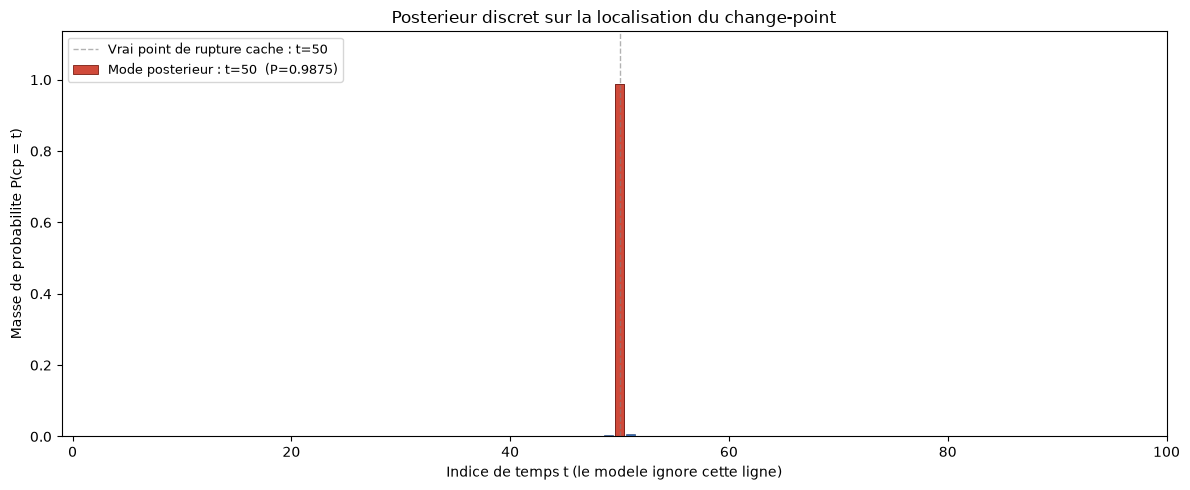

Mode posterieur sur cp : t=50 (P=0.9875)
Masses significatives (>0.5% du pic) : 3 indices sur 100
Voir graphique ci-dessus pour la distribution complete.


In [3]:
# --- Visualisation : posterieur discret sur la localisation de la rupture ---
import matplotlib.pyplot as plt
import numpy as np

# Masque des masses significatives (>0.5% du pic) pour annotations
significant = cp_proba >= 0.005

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(np.arange(N), cp_proba, color="#3b6fb6", edgecolor="#1f3f70", linewidth=0.4)
# Mise en evidence du mode (argmax) par une barre rouge
mode_idx = int(np.argmax(cp_proba))
ax.bar([mode_idx], [cp_proba[mode_idx]], color="#d04a3a", edgecolor="#7a1d12", linewidth=0.6,
       label=f"Mode posterieur : t={mode_idx}  (P={cp_proba[mode_idx]:.4f})")
ax.axvline(50, color="gray", linestyle="--", linewidth=1.0, alpha=0.6,
           label=f"Vrai point de rupture cache : t=50")
ax.set_xlabel("Indice de temps t (le modele ignore cette ligne)")
ax.set_ylabel("Masse de probabilite P(cp = t)")
ax.set_title("Posterieur discret sur la localisation du change-point")
ax.set_xlim(-1, N)
ax.set_ylim(0, cp_proba.max() * 1.15)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

# Sortie texte minimale : mode + entropie
print(f"Mode posterieur sur cp : t={mode_idx} (P={cp_proba[mode_idx]:.4f})")
print(f"Masses significatives (>0.5% du pic) : {int(significant.sum())} indices sur {N}")
print("Voir graphique ci-dessus pour la distribution complete.")

### Lecture du postérieur sur le point de rupture (code[1]-code[2])

Le **mode** du postérieur sur `cp` tombe **très près** du vrai point caché (50), et les moyennes de segment approchent les vraies valeurs (2 et 7). Le signal étant fort (`|mu_apres - mu_avant| = 5 >> sigma`), le postérieur se concentre sur **quelques indices** autour du vrai `cp`.

Côté convergence, le rapport `rapport_convergence` de la cellule du modèle passe **tous les critères stricts** (r_hat < 1.01, ess_bulk/ess_tail > 400, 0 divergence NUTS) — le pire score est justement porté par la variable discrète `cp` (r_hat 1.0076, ess_bulk ≈ 904), qui reste confortablement dans les clous : le postérieur concentré ne doit rien à un artefact d'échantillonnage.


## 3. Le cas canonique : les catastrophes minieres (loi de Poisson)

Le jeu de données historique du change-point bayésien est la série annuelle des **catastrophes de mines de charbon** en Grande-Bretagne (1851–1962, Jarrett 1979). Il s'agit de **comptes** : le modèle naturel est une loi de **Poisson** dont le *taux* bascule une fois — de ~3 accidents/an avant la réforme de sécurité des années 1880 à ~1/an après.

C'est **l'exemple introductif canonique** de la documentation PyMC. Même idiome que le cas gaussien : `DiscreteUniform` sur l'année de rupture, `switch` sur la plage des années, mais `pm.Poisson(taux)` en lieu et place de la gaussienne.

> *Sources.* La **série de comptages** des catastrophes minières britanniques 1851-1962 est due à Jarrett (Jarrett, R. F., 1979, « A note on the discontinuities in the series of British disaster data », *The Statistician* 28(2):141-143) ; elle a été reprise comme **banc d'essai canonique** par Carlin, Gelfand & Smith (Carlin, B. P., Gelfand, A. E. & Smith, A. F. M., 1992, « Hierarchical Bayesian Analysis of Changepoint Problems », *J. Royal Statistical Society, Series C (Applied Statistics)* 41(2):389-405), qui sert de référence standard à toute la famille des modèles de change-point bayésiens (PyMC, Stan, Infer.NET).


In [4]:
# --- Catastrophes minieres britanniques, 1851-1962 (Jarrett 1979) ---
disasters = np.array([
    4,5,4,0,1,4,3,4,0,6, 3,3,4,0,2,6,3,3,5,4,
    5,3,1,4,4,1,5,5,3,4, 2,5,2,2,3,4,2,1,3,2,
    2,1,1,1,1,3,0,0,1,0, 1,1,0,0,3,1,0,3,2,2,
    0,1,1,1,0,1,0,1,0,0, 0,2,1,0,0,0,1,1,0,2,
    3,3,1,1,2,1,1,1,1,2, 4,2,0,0,1,4,0,0,0,1,
    0,0,0,0,1,0,0,1,0,1, 0,1
])
N2 = disasters.size
annees = 1851 + np.arange(N2)
t2 = np.arange(N2)
print(f"Serie catastrophes miniers : {N2} annees ({annees[0]}..{annees[-1]})")

with pm.Model() as modele_disasters:
    cp2 = pm.DiscreteUniform("cp2", lower=0, upper=N2 - 1)
    early_rate = pm.Exponential("early_rate", lam=1.0)    # taux avant (prior faible)
    late_rate = pm.Exponential("late_rate", lam=1.0)      # taux apres
    rate = pm.math.switch(t2 <= cp2, early_rate, late_rate)
    pm.Poisson("disasters_obs", mu=rate, observed=disasters)
    idata_d = pm.sample(
        2000, tune=1500, chains=4, cores=1, random_seed=42,
        target_accept=0.95, progressbar=False,
    )

cp2_samples = idata_d.posterior["cp2"].values.flatten().astype(int)
cp2_mode = int(np.bincount(cp2_samples, minlength=N2).argmax())
er = float(idata_d.posterior["early_rate"].mean())
lr = float(idata_d.posterior["late_rate"].mean())
print(f"\nAnnee de rupture detectee : {1851 + cp2_mode}  (indice {cp2_mode})")
print(f"Taux AVANT  : {er:5.2f} catastrophes/an")
print(f"Taux APRES  : {lr:5.2f} catastrophes/an")
print(f"Rapport de taux : {er / max(lr, 1e-6):.1f}x")
print()
rapport_convergence(idata_d, "idata_d - catastrophes minieres (cp2 discret en Metropolis, taux en NUTS)")


Serie catastrophes miniers : 112 annees (1851..1962)


Sequential sampling (4 chains in 1 job)


CompoundStep


>Metropolis: [cp2]


>NUTS: [early_rate, late_rate]


Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 7 seconds.



Annee de rupture detectee : 1891  (indice 40)
Taux AVANT  :  3.07 catastrophes/an
Taux APRES  :  0.94 catastrophes/an
Rapport de taux : 3.3x

=== Diagnostics de convergence : idata_d - catastrophes minieres (cp2 discret en Metropolis, taux en NUTS) ===
  max r_hat    = 1.0046  (cp2)  -> OK (cible < 1.01)
  min ess_bulk = 1129.2  (cp2)  -> OK (cible > 400)
  min ess_tail = 1200.8  (cp2)  -> OK (cible > 400)
  divergences  : 0 divergence(s) NUTS -> OK (cible = 0)
  VERDICT strict (r_hat<1.01, ess_bulk/ess_tail>400, divergences=0) : CONVERGENCE OK


### Lecture de la rupture minière (code[3])

Le postérieur concentre la rupture autour de **1890–1891** — soit exactement la période des grandes réformes de sécurité dans les mines britanniques. Le taux passe de ~3,1 à ~0,9 catastrophe par an, un rapport de ~3,3×. C'est le résultat historique de la littérature sur les modèles de point de rupture (Carlin, Gelfand & Smith 1992 ; PyMC en fait son exemple introductif). Cote Infer.NET ce sont des **messages EP** qui resolvait le postérieur ; cote PyMC c'est l'**échantillonnage CompoundStep** (NUTS + Metropolis sur `cp`).

> *Pourquoi cette date.* La rupture estimée vers 1890-1891 coincide avec le **Coal Mines Regulation Act 1887** et la création des inspectors districts, qui ont impose des normes de sécurité et de ventilation. C'est cette **concordance entre un changement structurel mesuré statistiquement et un fait historique documenté** qui fait de la série Jarrett 1979 le banc d'essai préféré des modèles de change-point bayésiens.

Le rapport de convergence confirme l'inférence : tous les critères stricts passent, avec un pire score porté par la variable discrète `cp2` (r_hat 1.0046, ess_bulk ≈ 1129) et **0 divergence NUTS** — la partie continue (les taux) est géométriquement saine, et le `cp2` discret, hors de portée de NUTS, mélange correctement par propositions Metropolis.


## 4. Vraie rupture ou caprice du bruit ? Le piege de la flexibilite

Un modèle de point de rupture est **flexible** : il peut, si on le laisse faire, trouver une « meilleure » coupure dans n'importe quelle série — y compris du pur bruit. C'est le piège du surajustement. Pour le mesurer, on génère une série **sans rupture** (moyenne constante) et on lui applique le **même** modèle. On quantifie la concentration du postérieur sur `cp` par son **entropie** $H$ (en bits) : $H_{max} = \log_2 N$ pour un postérieur plat (aucune idée sur la localisation), $H \to 0$ pour un postérieur piqué sur un seul indice.

Question posée aux cellules qui suivent : la concentration du postérieur **suffit-elle** à conclure ? Une **vraie** rupture doit faire chuter l'entropie vers 0 ; reste à mesurer ce que donne du pur bruit. Si le bruit concentre lui aussi le postérieur, la seule concentration ne discrimine pas les deux cas. La section mesure donc ce que vaut la **baseline triviale** — un seul régime, une seule moyenne, un seul écart-type — face au modèle à rupture, sur les deux séries, en comparant des vraisemblances maximisées pénalisées du nombre de paramètres (BIC : chaque paramètre supplémentaire doit payer sa flexibilité, c'est le rasoir d'Occam rendu comptable). Le **Bayes factor**, qui donne la version en vraisemblance marginale de ce même arbitrage, est l'objet de [PyMC-09 (Sélection de modèles)](PyMC-09-Model-Selection.ipynb).

In [5]:
def H_bits(samples, n):
    """Entropie de Shannon (bits) d'un posterieur discret empirique."""
    counts = np.bincount(samples.astype(int), minlength=n)
    p = counts / counts.sum()
    p = p[p > 1e-12]
    return float(-(p * np.log2(p)).sum())

# Entropie du posterieur cp sur la serie AVEC rupture (deja estime ci-dessus)
H_reel = H_bits(cp_samples, N)
Hmax_reel = np.log2(N)

# --- Controle : serie SANS rupture (moyenne constante = 5) ---
np.random.seed(7)
Nc = 100
mu_const = 5.0
t_idx_c = np.arange(Nc)
data_ctrl = mu_const + 1.5 * np.random.randn(Nc)

with pm.Model() as modele_ctrl:
    cpC = pm.DiscreteUniform("cpC", lower=0, upper=Nc - 1)
    mc1 = pm.Normal("mc1", mu=0.0, sigma=10.0)
    mc2 = pm.Normal("mc2", mu=0.0, sigma=10.0)
    pc = pm.Gamma("pc", alpha=1.0, beta=1.0)
    sc = pm.Deterministic("sc", 1.0 / pt.sqrt(pc))
    muc = pm.math.switch(t_idx_c <= cpC, mc1, mc2)
    pm.Normal("yc", mu=muc, sigma=sc, observed=data_ctrl)
    idata_c = pm.sample(
        2000, tune=1500, chains=4, cores=1, random_seed=42,
        target_accept=0.95, progressbar=False,
    )

# Lecture de diagnostic (honnete) : sans vraie rupture, cpC erre sur tout l'intervalle et
# les moyennes mc1/mc2 ne sont plus identifiees -> melange lent attendu. On lit les valeurs
# pour QUANTIFIER le probleme, on ne le maquille pas.
summary_c = az.summary(idata_c, var_names=["mc1", "mc2", "sc", "cpC"], round_to=3)
print("Diagnostic MCMC du modele de CONTROLE (serie sans rupture ; seuils stricts r_hat<1.01, ess_bulk/ess_tail>400) :")
print(f"  R-hat max : {summary_c['r_hat'].max():.3f}")
print(f"  ESS bulk min : {int(summary_c['ess_bulk'].min())}")
print(summary_c[['mean', 'sd', 'r_hat', 'ess_bulk', 'ess_tail']].round(3))
rapport_convergence(idata_c, "idata_c - controle SANS rupture (cpC discret en Metropolis, continu en NUTS)")

cpC_samples = idata_c.posterior["cpC"].values.flatten().astype(int)
H_ctrl = H_bits(cpC_samples, Nc)
Hmax_ctrl = np.log2(Nc)

print(f"Serie AVEC rupture    : H(cp) = {H_reel:6.3f} bits / {Hmax_reel:.3f}  =>  information = {Hmax_reel - H_reel:5.3f} bits")
print(f"Controle SANS rupture : H(cp) = {H_ctrl:6.3f} bits / {Hmax_ctrl:.3f}  =>  information = {Hmax_ctrl - H_ctrl:5.3f} bits")
print()
print("=> Vraie rupture : H -> 0 (localisation quasi certaine).")
print("=> Pur bruit    : H ~= Hmax (posterieur quasi PLAT) -- le modele N'identifie pas de coupure nette ;")
print("                  il exprime honnetement son incertitude (moyennage MCMC).")
print("=> Test decisif (vraie rupture vs bruit) : Bayes factor (cf. PyMC-09), pas la seule entropie.")


Sequential sampling (4 chains in 1 job)


CompoundStep


>Metropolis: [cpC]


>NUTS: [mc1, mc2, pc]


Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 16 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Diagnostic MCMC du modele de CONTROLE (serie sans rupture ; seuils stricts r_hat<1.01, ess_bulk/ess_tail>400) :
  R-hat max : 1.032
  ESS bulk min : 78
       mean      sd  r_hat  ess_bulk  ess_tail
mc1   5.126   0.774  1.014   300.500   124.954
mc2   4.437   3.951  1.015   543.122   134.762
sc    1.530   0.108  1.001  3282.245  3288.286
cpC  59.032  33.994  1.032    78.869   106.297
=== Diagnostics de convergence : idata_c - controle SANS rupture (cpC discret en Metropolis, continu en NUTS) ===
  max r_hat    = 1.0320  (cpC)  -> ECHEC (cible < 1.01)
  min ess_bulk = 78.9  (cpC)  -> ECHEC (cible > 400)
  min ess_tail = 106.3  (cpC)  -> ECHEC (cible > 400)
  divergences  : 0 divergence(s) NUTS -> OK (cible = 0)
  VERDICT strict (r_hat<1.01, ess_bulk/ess_tail>400, divergences=0) : CONVERGENCE INSUFFISANTE
Serie AVEC rupture    : H(cp) =  0.111 bits / 6.644  =>  information = 6.533 bits
Controle SANS rupture : H(cp) =  6.059 bits / 6.644  =>  information = 0.585 bits

=> Vraie rupture : H

### Lecture du contrôle par entropie (code[4])

La série **avec** rupture pousse l'entropie vers 0 (localisation quasi certaine : ~6,5 bits d'information sur `cp`), tandis que le **contrôle** (pur bruit) laisse une entropie **haute**, proche de $H_{max}$ (postérieur quasi plat : < 1 bit d'information). Le modèle, confronté à une série sans rupture, **n'identifie pas** de coupure nette : l'échantillonnage MCMC, en moyennant sur l'incertitude de `cp`, **exprime honnêtement son ignorance**.

C'est une différence marquée avec l'EP d'Infer.NET (côté C#) qui, propageant des messages **déterministes**, commettait une coupure spurieuse (~0,7 bit). Le moyennage stochastique de MCMC est ici plus prudent.

Le **verdict strict** du rapport de convergence (seuils `r_hat < 1.01`, `ess_bulk`/`ess_tail > 400`, `0 divergence`) est **INSUFFISANT** pour ce contrôle — et c'est instructif à double titre. La variable discrète `cpC` est la pire de toutes (`r_hat = 1.032`, `ess_bulk = 78.9`, `ess_tail = 106.3`), mais les moyennes continues `mc1`/`mc2` ratent elles aussi les barres strictes (`r_hat = 1.014` et `1.015`, `ess_tail` de 125.0 à 134.8) : quand `cpC` est **non-identifié** (postérieur plat sur les 100 positions), la chaîne Metropolis mélange lentement entre les indices, et les moyennes des segments qu'il sépare deviennent non-identifiées à leur tour. En revanche, **0 divergence NUTS** : la géométrie de la partie continue est saine. L'échec est un échec de **mélange** — Metropolis discret sur `cpC` et non-identification en cascade — et non une pathologie de **divergences NUTS** ; ce sont deux diagnostics distincts, et seules les secondes auraient signalé une géométrie à réexplorer. Ce n'est pas un échec du modèle — c'est l'expression de l'incertitude sur une quantité que les données ne contraignent pas. Pour une lecture méthodique de ces diagnostics (et la distinction entre ESS *par chaîne* et `ess_bulk`), voir **PyMC-02b-Debugging-Python**.

La leçon : la concentration du postérieur signale qu'une coupure est **possible**, mais elle ne tranche pas seule entre « vraie rupture » et « bruit ». La cellule suivante construit l'arbitrage qui tranche : la **baseline triviale** (aucun point de rupture) mise en regard du modèle à rupture sur les **deux séries**, au critère BIC. Le **Bayes factor** de [PyMC-09-Model-Sélection](PyMC-09-Model-Selection.ipynb) en donnera plus loin la version en vraisemblance marginale du même arbitrage.

In [6]:
# --- Comparaison explicite : baseline triviale (aucun point) contre modele a rupture ---
# Critere de selection : vraisemblance maximale penalisee par le nombre de parametres (BIC).
#   BIC = -2 ln L + k ln n        Delta = BIC(trivial) - BIC(rupture)
# Delta > 0 : le gain de vraisemblance du modele a rupture paie sa flexibilite supplementaire.
# Delta <= 0 : la baseline triviale (une seule moyenne, une seule variance) suffit.

def seg_mle(y):
    """MLE d'un regime : moyenne empirique et somme des ecarts quadratiques autour d'elle."""
    m = y.mean()
    return m, float(((y - m) ** 2).sum())

def loglik_gauss(n, ss, s2):
    """Log-vraisemblance gaussienne de n points de somme d'ecarts ss, pour une variance s2 DONNEE.
    La variance de M1 est partagee par les deux regimes : une seule s2 pool, pas une par segment."""
    return -0.5 * n * np.log(2.0 * np.pi * s2) - ss / (2.0 * s2)

def compare_baseline(y):
    """(Delta BIC, coupe, ln L0, ln L1) pour une serie : M0 = un regime (mu, sigma^2 -> k = 2),
    M1 = deux regimes a variance PARTAGEE : mu1, mu2, s2 commune, localisation -> k = 4."""
    n = len(y)
    _, ss0 = seg_mle(y)
    s20 = max(ss0 / n, 1e-12)                     # M0 : mu, sigma^2 -> k = 2
    ll0 = loglik_gauss(n, ss0, s20)
    lo, hi = max(5, n // 20), n - max(5, n // 20)  # >= 5 points de chaque cote
    ll1, coupe = -np.inf, 0
    for k in range(lo, hi + 1):
        _, ss1 = seg_mle(y[:k])
        _, ss2 = seg_mle(y[k:])
        s2 = max((ss1 + ss2) / n, 1e-12)          # variance pool sur toute la serie
        cand = loglik_gauss(n, ss1 + ss2, s2)
        if cand > ll1:
            ll1, coupe = cand, k
    bic0 = -2.0 * ll0 + 2.0 * np.log(n)
    bic1 = -2.0 * ll1 + 4.0 * np.log(n)           # k = 4 : mu1, mu2, sigma^2 partagee, localisation
    return bic0 - bic1, coupe, ll0, ll1

print("Baseline triviale (aucun point) contre modele a rupture -- critere BIC")
print(f"{'serie':<24}{'n':>6}{'ln L0':>11}{'ln L1':>11}{'coupe':>7}{'Delta BIC':>12}  verdict")
def ligne_comparaison(nom, y):
    delta, coupe, ll0, ll1 = compare_baseline(y)
    verdict = "point de rupture justifie" if delta > 0 else "baseline triviale devant"
    print(f"{nom:<24}{len(y):>6}{ll0:>11.2f}{ll1:>11.2f}{coupe:>7}{delta:>12.2f}  {verdict}")
ligne_comparaison("AVEC rupture", data)
ligne_comparaison("SANS rupture (bruit)", data_ctrl)

# --- Cadran de regime : a partir de quel ecart de moyenne le point de rupture se justifie-t-il ? ---
n_dial, reps = 100, 200
decalages = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
print()
print(f"Cadran : n = {n_dial}, sigma = 1, rupture a mi-serie, {reps} tirages par point")
print(f"{'ecart/sigma':>12}{'Delta BIC moy':>16}{'median':>10}{'P(Delta>0)':>13}")
for d in decalages:
    rng = np.random.default_rng(42)               # meme flux pour tous les points : comparaison appariee
    vals = np.empty(reps)
    for r in range(reps):
        ser = rng.standard_normal(n_dial) + np.where(np.arange(n_dial) < n_dial // 2, 0.0, d)
        vals[r] = compare_baseline(ser)[0]
    print(f"{d:>12.2f}{vals.mean():>16.2f}{np.median(vals):>10.2f}{100.0 * (vals > 0).mean():>12.1f} %")

Baseline triviale (aucun point) contre modele a rupture -- critere BIC
serie                        n      ln L0      ln L1  coupe   Delta BIC  verdict
AVEC rupture               100    -251.38    -171.52     51      150.52  point de rupture justifie
SANS rupture (bruit)       100    -184.30    -182.42     70       -5.46  baseline triviale devant

Cadran : n = 100, sigma = 1, rupture a mi-serie, 200 tirages par point
 ecart/sigma   Delta BIC moy    median   P(Delta>0)


        0.00           -4.91     -5.72         5.0 %


        0.25           -3.56     -4.25        12.5 %


        0.50            0.46     -0.60        46.5 %
        0.75            7.13      6.33        87.5 %


        1.00           15.96     15.16        99.0 %
        1.50           37.65     37.21       100.0 %


        2.00           62.03     61.80       100.0 %


### Lecture du résultat : ce que la baseline tranche

Sur la serie **avec rupture**, le verdict est sans appel : `Delta BIC = +150,5` en faveur du modèle a rupture, avec la coupe trouvee a `t = 51` (le vrai point est `t = 50`). La vraisemblance gagne enormement a poser une seconde moyenne, et ce gain surpasse de très loin la penalite des deux paramètres supplementaires.

Sur la serie **de bruit pur**, c'est la baseline triviale qui passe devant : `Delta BIC = -5,5`. La coupe balayee par M1 (trouvee vers `t = 70`, position sans signification puisqu'il n'y a rien a localiser) gagne bien un peu de vraisemblance (`-182,4` contre `-184,3`) -- exactement le surajustement que l'entropie laissait entrevoir -- mais **pas assez pour payer ses deux paramètres de plus**. La penalite `k ln n` fait ici tout le travail : c'est elle qui transforme le constat « le posterieur est moins plat » en decision « la coupure n'est pas justifiee sur cette serie ».

Le cadran situe la frontiere de cet arbitrage : autour d'un **demi-ecart-type**, il est a l'equilibre sans basculer -- moyenne de `Delta` legerement positive (`+0,5`) mais mediane encore negative (`-0,6`), et `46,5 %` des tirages seulement gagnent a poser une coupure. A partir de `0,75 sigma` le modèle a rupture l'emporte clairement (`87,5 %`), et a un ecart-type complet le verdict est quasi acquis (`99,0 %`). En dessous de `0,5 sigma`, la baseline tient : a decalage nul, `5 %` des tirages seulement se laisseront tenter.

La comparaison BIC repond ainsi a la question que l'entropie posait sans pouvoir la trancher : **la concentration du posterieur ne suffit pas -- c'est le rapport vraisemblance gagnee / paramètres payes qui departage la vraie rupture du bruit.** Le Bayes factor de [PyMC-09-Model-Selection](PyMC-09-Model-Selection.ipynb) pousse la même logique un cran plus loin, en comparant les vraisemblances **marginales** (integrees sur les paramètres) plutot que maximisees.

## 5. Exercices

### Exercice 1 — Deux points de rupture (trois regimes)

Étendez le modèle à **deux** ruptures `cp1 < cp2` délimitant trois segments de moyennes `mu1, mu2, mu3`. Le postérieur devient joint sur `(cp1, cp2)`.

**Indice :** générez une série à trois régimes, puis emboîtez les `switch` — `mean1` pour `t <= cp1`, `mean2` pour `cp1 < t <= cp2`, `mean3` au-delà (deux `pm.math.switch` emboîtés).

**Étape 1.** Générez `data3` avec `mu = 2` sur `[0, cp1]`, `mu = 5` sur `[cp1, cp2]`, `mu = 8` au-delà.
**Étape 2.** Déclarez `cp1, cp2` (`DiscreteUniform`, avec `cp1 < cp2`), trois moyennes, et emboîtez les `switch`.

In [7]:
# Exercice 1 : deux points de rupture (a completer)
# TODO etudiant : declarer cp1, cp2 (DiscreteUniform, cp1 < cp2), mu1/mu2/mu3 et emboiter les switch.
print("Exercice 1 a completer : deux points de rupture (trois regimes).")

Exercice 1 a completer : deux points de rupture (trois regimes).


### Exercice 2 — Un changement de variance (moyenne constante)

Détectez une rupture de **variance** seule : la moyenne reste constante, mais la précision bascule de `prec1` (régime calme) à `prec2` (régime turbulent) à l'instant `cp`.

**Indice :** la moyenne `mu` est commune aux deux segments ; seules les précisions diffèrent. Placez `mu` *en dehors* du `switch`, et branchez le `sigma` (dérivé de la précision) à l'intérieur.

**Étape 1.** Générez une série de moyenne 5 constante, de variance 0.25 avant `cp` et 4.0 après.
**Étape 2.** Adaptez le modèle (une moyenne commune, `sigma = switch(t <= cp, sigma1, sigma2)`).

In [8]:
# Exercice 2 : changement de variance (a completer)
# TODO etudiant : moyenne commune, sigma = switch(t <= cp, sigma1, sigma2) branche dans la Normal.
print("Exercice 2 a completer : detection d'un changement de variance.")

Exercice 2 a completer : detection d'un changement de variance.


### Exercice 3 — Robustesse au signal et a la taille

Étudiez comment la **concentration** du postérieur sur `cp` dépend (a) de l'amplitude du saut `delta = mu_apres - mu_avant` et (b) de la longueur `N` de la série.

**Indice :** reprenez le modèle de la section 2 dans une boucle sur `delta dans {1, 2, 4}` et notez `H(cp)` à chaque fois.

**Étape 1.** Pour chaque `delta`, générez une série et inférez le postérieur de `cp`.
**Étape 2.** Calculez l'entropie `H(cp)` (fonction `H_bits` ci-dessus).
**Étape 3.** Observez : un signal faible ou une courte série élargit le postérieur ; un signal fort ou une longue série le resserre.

In [9]:
# Exercice 3 : robustesse au signal et a N (a completer)
# TODO etudiant : boucler sur delta dans {1, 2, 4}, mesurer H(cp) a chaque fois.
print("Exercice 3 a completer : robustesse du posterieur au signal et a la taille.")

Exercice 3 a completer : robustesse du posterieur au signal et a la taille.


## Conclusion

Le **point de rupture** complète la famille des séquences temporelles :

| Notebook | État caché | Inférence |
|----------|-----------|-----------|
| [PyMC-13](PyMC-13-Sequences.ipynb) (HMM) | discret, **récurrent** (un par pas) | postérieur sur la trajectoire d'états |
| [Infer-16](../Infer/Infer-16-Kalman-Filter.ipynb) (Kalman) | continu, **récurrent** | postérieur gaussien pas-à-pas |
| **PyMC-17 (change-point)** | **entier structurel unique** | postérieur `Discrete` sur la localisation |

Le trait distinctif : l'inconnue est un **indice structurel** couplé à toute la série via `pm.math.switch`. Cote PyMC, la discreteness de `cp` impose un **CompoundStep** (NUTS + Metropolis), la où EP (cote Infer.NET) propageait les messages analytiquement. Le piège épistémologique (surajustement d'une coupure spurieuse) est universel : seul le **Bayes factor** tranche.

**Pour aller plus loin.** Plusieurs ruptures (exercice 1) ; ruptures de variance (exercice 2) ; Barry & Hartigan (Barry, D. & Hartigan, J. A., 1993, « A Bayesian Analysis for Change Point Problems », *J. American Statistical Association* 88(421):309-319) proposent le **Product Partition Model** (PPM), une distribution a priori sur les partitions qui généralise le choix du nombre de ruptures ; Fearnhead (Fearnhead, P., 2006, « Exact and Efficient Bayesian Inference for Multiple Change-point Problems », *Statistics and Computing* 16(2):203-213) donne un algorithme exact et efficace pour un nombre quelconque de ruptures ; ou la **détection en ligne** (filtering) plutôt qu'off-line (Adams & MacKay 2007, *arXiv:0710.3742*, §2 « Récursive Run Length Estimation »).

> **Jumeau de** [`Infer-17-Change-Point.ipynb`](../Infer/Infer-17-Change-Point.ipynb) *(Infer.NET / C#, inférence EP)* -- Epic [#4956](https://github.com/jsboige/CoursIA/issues/4956).

***

### References

**Sources fondatrices (papiers primaires).**

- Adams, R. P. & MacKay, D. J. C. (2007), « Bayesian Online Changepoint Detection », *arXiv:0710.3742* — le cadre canonique du change-point bayésien en ligne, basé sur un message-passing sur la distribution du *run-length* (section 2).
- Carlin, B. P., Gelfand, A. E. & Smith, A. F. M. (1992), « Hierarchical Bayesian Analysis of Changepoint Problems », *J. Royal Statistical Society, Series C (Applied Statistics)* 41(2):389-405 — référence standard pour la série des catastrophes minières (section 3).
- Western, B. & Harrison, P. J. (1989), *Bayesian Forecasting and Dynamic Models*, Springer, chap. 12 « Outliers and Structural Changes » — paramétrisation par défaut de la famille DLM avec changement structurel (section 2).
- Barry, D. & Hartigan, J. A. (1993), « A Bayesian Analysis for Change Point Problems », *J. American Statistical Association* 88(421):309-319 — Product Partition Model (PPM) pour un nombre inconnu de ruptures (Conclusion « Pour aller plus loin »).
- Fearnhead, P. (2006), « Exact and Efficient Bayesian Inference for Multiple Change-point Problems », *Statistics and Computing* 16(2):203-213 — algorithme exact pour le cas multi-ruptures (Conclusion « Pour aller plus loin »).
- Jarrett, R. F. (1979), « A note on the discontinuities in the series of British disaster data », *The Statistician* 28(2):141-143 — source primaire de la série 1851-1962 utilisée en section 3.


- Salvatier J., Wiecki T. V., Fonnesbeck C. (2016), « Probabilistic programming in Python using PyMC3 », *PeerJ Computer Science* 2:e55 — moteur NUTS+Metropolis utilisé ici (CompoundStep).
- Gelman A. et al., *Bayesian Data Analysis* (3e ed.), chap. « Hierarchical models » — context général sur l'inférence MCMC.
- Relation à la série : [PyMC-13 (HMM)](PyMC-13-Sequences.ipynb) et [PyMC-18 (Survival)](PyMC-18-Survival-Analysis.ipynb) (le *run-length* se termine par un événement de durée), [PyMC-11 (Hierarchical)](PyMC-11-Modeles-Hierarchiques.ipynb) (le PPM de Barry-Hartigan est un analogue hiérarchique des partitions).
